# 02 — Exploratory Data Analysis

Answers the core equity and infrastructure questions using the cleaned tables from
`01_data_cleaning.ipynb`:

- What share of the population has *basic* water access, and where is it worst?
- Which provinces have the longest queues?
- How contaminated are the wells?
- How much has the improvement program invested, and how efficiently?
- Who bears the burden of queueing — and (with an explicit time-period caveat) what does the
  historical crime data show near water sources?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

water_source = pd.read_csv("../data/water_source.csv")
location = pd.read_csv("../data/location.csv")
visits = pd.read_csv("../data/visits.csv", parse_dates=["time_of_record"])
well_pollution = pd.read_csv("../data/well_pollution.csv")
project_progress = pd.read_csv("../data/project_progress.csv", parse_dates=["date_started", "date_of_completion"])
vendors = pd.read_csv("../data/vendors.csv")
queue_composition = pd.read_csv("../data/queue_composition.csv")
crime = pd.read_csv("../data/water_source_related_crime.csv")

print(f"Total population represented: {water_source['number_of_people_served'].sum():,}")
print(f"Water sources: {len(water_source):,} across {location['province_name'].nunique()} provinces, {location['town_name'].nunique()} towns")


Total population represented: 27,628,140
Water sources: 39,650 across 5 provinces, 31 towns


## Defining and measuring \"basic water access\"

In [2]:
water_source["location_id"] = water_source["source_id"].str[:-3]
ws = water_source.merge(location, on="location_id", how="left")

avg_queue = visits.groupby("source_id")["time_in_queue"].mean().rename("avg_queue")
ws = ws.merge(avg_queue, on="source_id", how="left")

def classify(row):
    t = row["type_of_water_source"]
    if t == "tap_in_home":
        return "Basic access"
    if t in ("tap_in_home_broken", "river"):
        return "No access (broken)" if t == "tap_in_home_broken" else "No access (surface water)"
    if pd.isna(row["avg_queue"]) or row["avg_queue"] < 30:
        return "Basic access"
    return "Limited access (queue 30min+)"

ws["access_level"] = ws.apply(classify, axis=1)
access_summary = ws.groupby("access_level")["number_of_people_served"].sum().sort_values(ascending=False)
access_pct = (access_summary / access_summary.sum() * 100).round(1)

print(access_summary)
print()
print(access_pct.astype(str) + "%")


access_level
Basic access                     12742712
Limited access (queue 30min+)     8723164
No access (broken)                3799720
No access (surface water)         2362544
Name: number_of_people_served, dtype: int64

access_level
Basic access                     46.1%
Limited access (queue 30min+)    31.6%
No access (broken)               13.8%
No access (surface water)         8.6%
Name: number_of_people_served, dtype: str


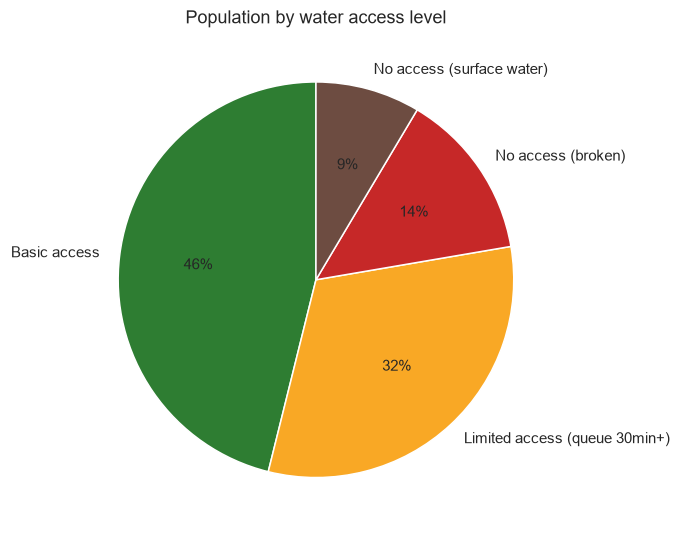

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
colors = {"Basic access": "#2E7D32", "Limited access (queue 30min+)": "#F9A825",
          "No access (broken)": "#C62828", "No access (surface water)": "#6D4C41"}
access_summary.plot.pie(ax=ax, autopct="%1.0f%%", colors=[colors[i] for i in access_summary.index],
                          ylabel="", startangle=90)
ax.set_title("Population by water access level")
plt.tight_layout()
plt.savefig("../images/access_level_breakdown.png", dpi=130, bbox_inches="tight")
plt.show()


**Only 46% of Maji Ndogo's 27.6 million represented population has basic water access.**
13.8% rely on infrastructure that's already broken (in-home taps that no longer work), and 8.6%
still depend on unimproved surface water (rivers). The remaining 31.6% technically have an
improved source, but the queue is long enough (30+ minutes on average) that it no longer counts
as basic access under the WHO/JMP standard used here.

## Access by province (choropleth)

In [4]:
province_access = ws.groupby("province_name").apply(
    lambda g: pd.Series({
        "total_pop": g["number_of_people_served"].sum(),
        "basic_pop": g.loc[g["access_level"] == "Basic access", "number_of_people_served"].sum(),
    })
)
province_access["pct_basic"] = (province_access["basic_pop"] / province_access["total_pop"] * 100).round(1)
province_access = province_access.sort_values("pct_basic")
print(province_access)


               total_pop  basic_pop  pct_basic
province_name                                 
Sokoto           5774434    2432676       42.1
Kilimani         6584764    2910346       44.2
Amanzi           5431826    2468144       45.4
Hawassa          3843810    1921432       50.0
Akatsi           5993306    3010114       50.2


In [5]:
import plotly.express as px

with open("../data/provinces.geojson") as f:
    geo = json.load(f)

df_map = province_access.reset_index().rename(columns={"province_name": "province_key"})

fig = px.choropleth(
    df_map, geojson=geo, locations="province_key", featureidkey="properties.province_key",
    color="pct_basic", color_continuous_scale="RdYlGn", range_color=(35, 55),
    labels={"pct_basic": "% Basic Access"},
)
fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(title="Basic Water Access by Province", margin=dict(l=0, r=0, t=40, b=0))
fig.write_image("../images/access_choropleth.png", width=800, height=600, scale=2)
fig.show()


**Sokoto is the worst-served province at 42.1% basic access; Akatsi is the best at 50.2%.**
Even the best-performing province still leaves roughly half its population without basic access
— this is a system-wide gap, not one province's problem.

## Queue times by province

province_name
Kilimani    67.1
Akatsi      62.4
Amanzi      57.5
Sokoto      57.1
Hawassa     55.8
Name: time_in_queue, dtype: float64


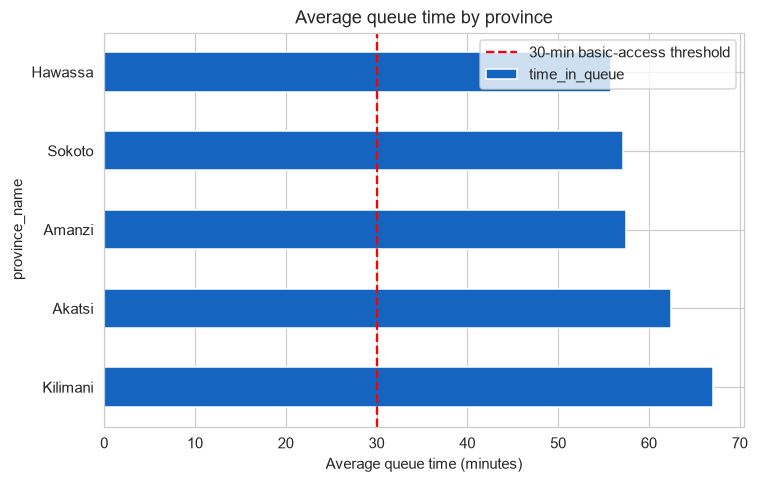

In [6]:
queue_by_province = visits.merge(location, left_on=visits["source_id"].str[:-3], right_on="location_id") \
    .groupby("province_name")["time_in_queue"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
queue_by_province.plot.barh(ax=ax, color="#1565C0")
ax.set_xlabel("Average queue time (minutes)")
ax.axvline(30, color="red", linestyle="--", label="30-min basic-access threshold")
ax.legend()
ax.set_title("Average queue time by province")
plt.tight_layout()
plt.savefig("../images/queue_time_by_province.png", dpi=130, bbox_inches="tight")
plt.show()
print(queue_by_province.round(1))


## Well water quality

results
Contaminated: Chemical      7093
Contaminated: Biological    5374
Clean                       4916
Name: count, dtype: int64
results
Contaminated: Chemical      40.8
Contaminated: Biological    30.9
Clean                       28.3
Name: count, dtype: float64


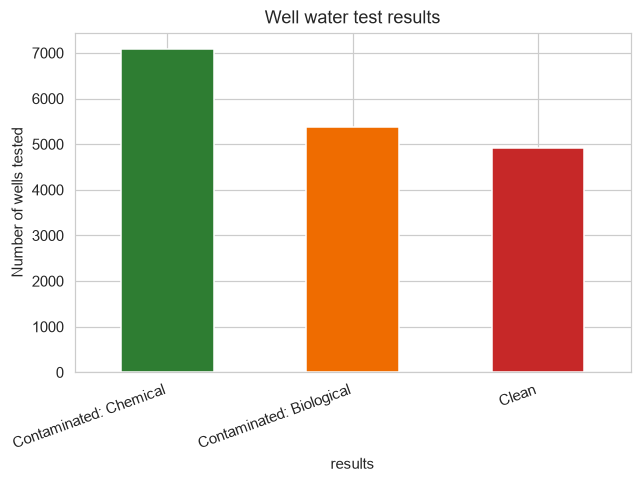

In [7]:
results_summary = well_pollution["results"].value_counts()
fig, ax = plt.subplots(figsize=(6, 4.5))
results_summary.plot.bar(ax=ax, color=["#2E7D32", "#EF6C00", "#C62828"])
ax.set_title("Well water test results")
ax.set_ylabel("Number of wells tested")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("../images/well_pollution.png", dpi=130, bbox_inches="tight")
plt.show()
print(results_summary)
print((results_summary / results_summary.sum() * 100).round(1))


**71.7% of tested wells are contaminated** — 40.8% chemically, 30.9% biologically. Wells are
the second-most-used source type after shared taps; this contamination rate makes well water
quality one of the more urgent findings in the dataset, independent of the queue-time access
metric above (a well can have a short queue and still be making people sick).

## Infrastructure investment and vendor efficiency

Total invested to date: $154,493,298 across 25,398 completed projects
                                  n  avg_cost  avg_days
improvement                                            
Install RO filter              7093    5929.2       0.8
Diagnose local infrastructure  5856     551.6       0.8
Install UV and RO filter       5374    4335.8       1.6
Drill well                     3379   12154.6       6.1
Install 1 taps nearby          1037    3042.0       6.7
Install 8 taps nearby           760   22364.2      37.8
Install 7 taps nearby           360   19822.0      32.9
Install 4 taps nearby           342   11490.3      20.2
Install 5 taps nearby           308   14296.5      24.2
Install 2 taps nearby           307    5704.0      11.6
Install 3 taps nearby           300    8778.0      15.6
Install 6 taps nearby           282   17132.9      29.2


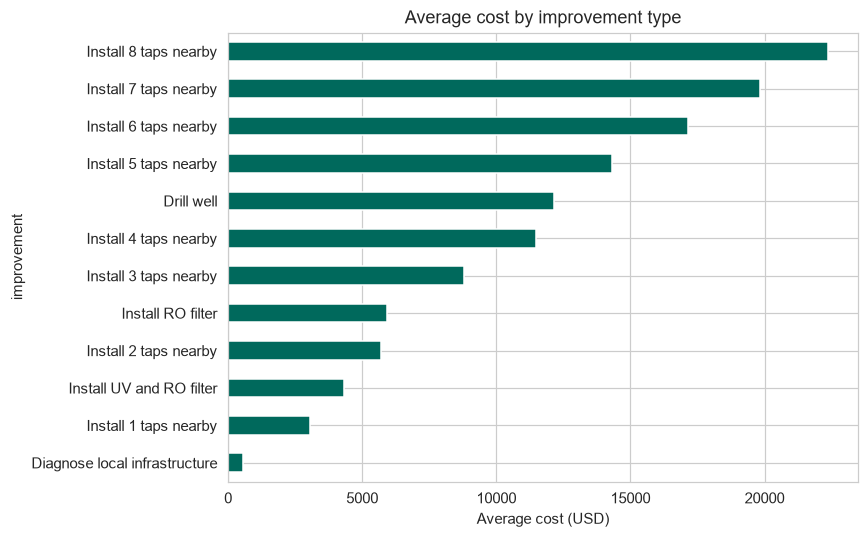

In [8]:
completed = project_progress[project_progress["source_status"] == "Complete"].copy()
completed["days_to_complete"] = (completed["date_of_completion"] - completed["date_started"]).dt.days

total_invested = completed["cost"].sum()
print(f"Total invested to date: ${total_invested:,.0f} across {len(completed):,} completed projects")

by_improvement = completed.groupby("improvement").agg(
    n=("project_id", "count"), avg_cost=("cost", "mean"), avg_days=("days_to_complete", "mean")
).sort_values("n", ascending=False)
print(by_improvement.round(1))

fig, ax = plt.subplots(figsize=(8, 5))
by_improvement["avg_cost"].sort_values().plot.barh(ax=ax, color="#00695C")
ax.set_xlabel("Average cost (USD)")
ax.set_title("Average cost by improvement type")
plt.tight_layout()
plt.savefig("../images/cost_by_improvement.png", dpi=130, bbox_inches="tight")
plt.show()


In [9]:
vendor_perf = completed.merge(vendors, left_on="assigned_vendor", right_on="vendor_ID") \
    .groupby("company_name").agg(n_projects=("project_id", "count"), avg_cost=("cost", "mean")) \
    .query("n_projects >= 50").sort_values("avg_cost")

print("Most cost-efficient vendors (min. 50 completed projects):")
print(vendor_perf.head(10).round(0))
print()
print("Least cost-efficient vendors (min. 50 completed projects):")
print(vendor_perf.tail(5).round(0))


Most cost-efficient vendors (min. 50 completed projects):
                                  n_projects  avg_cost
company_name                                          
Lusaka Structural Analysis               917     504.0
Gaborone Civic Diagnostics               964     541.0
Aswan Infrastructure Diagnostics         905     543.0
Bamako Survey Co.                       1157     566.0
Kano Urban Planning                      911     567.0
Mombasa Engineering Insights            1002     583.0
Kisangani Filter Solutions               545    4327.0
Mwanza Water Purification                652    4634.0
Timbuktu UV Systems                      537    4758.0
Banjul Filtration Tech                   541    4845.0

Least cost-efficient vendors (min. 50 completed projects):
                          n_projects  avg_cost
company_name                                  
Menengai Flow Tech                67   13672.0
Nyungwe Pipeline Experts          62   14120.0
Turkana Water Tech                

The improvement program has invested **$154.5 million** across 25,398 completed projects.
Cost per project varies enormously by type — from ~$552 for a diagnostic visit to ~$22,000 for
installing 8 new taps — so "average cost per project" alone would be a misleading efficiency
metric; cost has to be compared within improvement type, which is what the vendor ranking above
does.

## Who bears the burden of queueing?

percent_male      23.1
percent_female    69.1
percent_child      7.9
dtype: float64


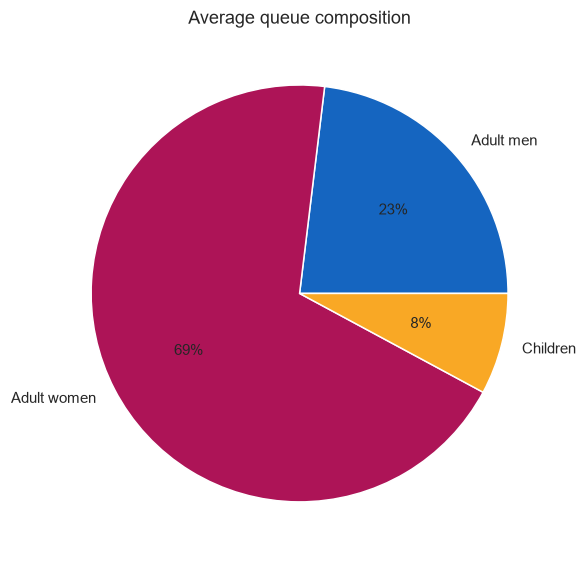

In [10]:
queue_demo = queue_composition[["percent_male", "percent_female", "percent_child"]].mean()
fig, ax = plt.subplots(figsize=(5.5, 5.5))
queue_demo.plot.pie(ax=ax, autopct="%1.0f%%", labels=["Adult men", "Adult women", "Children"],
                      colors=["#1565C0", "#AD1457", "#F9A825"], ylabel="")
ax.set_title("Average queue composition")
plt.tight_layout()
plt.savefig("../images/queue_demographics.png", dpi=130, bbox_inches="tight")
plt.show()
print(queue_demo.round(1))


**Women make up 69% of the average queue, children 8%, men 23%.** Water collection time is
overwhelmingly a burden borne by women — a well-documented pattern in water-access research
globally, and one this dataset reproduces clearly.

## Crime near water sources — with an explicit caveat

As established in the cleaning notebook, **this crime data (2010–2020) does not overlap in
time with the visits data (2021–2023)**. The chart below describes historical crime patterns at
these locations; it is *not* evidence about current queueing conditions, and no time-based causal
claim is made here.

Victim gender share:
victim_gender
F    64.4
M    25.4
C    10.2
Name: proportion, dtype: float64


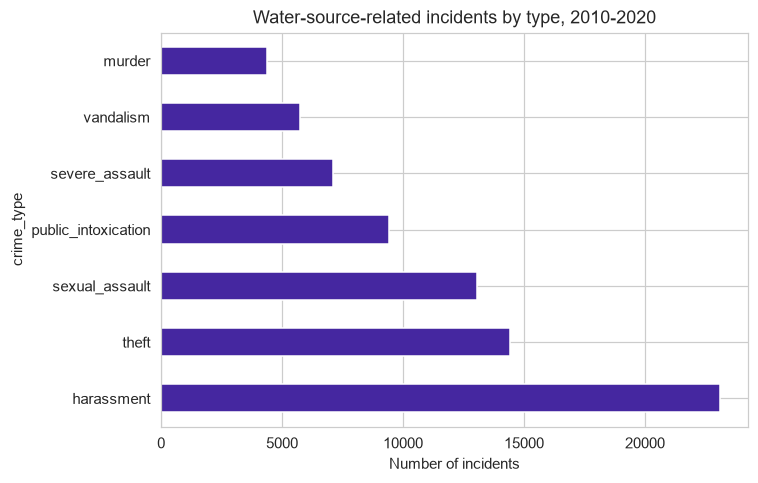

In [11]:
crime_summary = crime["crime_type"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4.5))
crime_summary.plot.barh(ax=ax, color="#4527A0")
ax.set_title("Water-source-related incidents by type, 2010-2020")
ax.set_xlabel("Number of incidents")
plt.tight_layout()
plt.savefig("../images/crime_by_type.png", dpi=130, bbox_inches="tight")
plt.show()

gender_summary = crime["victim_gender"].value_counts(normalize=True).mul(100).round(1)
print("Victim gender share:")
print(gender_summary)


Harassment (23,104), theft (14,431), and sexual assault (13,065) are the three most common
incident types. **64.4% of recorded victims are female.** Combined with the queueing-burden
finding above, this points to water collection as a location of real, gendered physical risk in
this population — reported here factually and without embellishment, consistent with how this
kind of finding is handled in WASH (water/sanitation/hygiene) sector research.

## EDA takeaways carried into the report

1. Only 46% basic water access system-wide; Sokoto is worst (42.1%), Akatsi best (50.2%) — but
   every province still leaves roughly half its population underserved.
2. 71.7% of tested wells are contaminated (chemical or biological) — a health issue independent
   of queue-time access.
3. $154.5M invested across 25,398 completed improvement projects; vendor cost-efficiency varies
   more than 8x within the same improvement type.
4. Women carry 69% of queueing time; historical crime data (non-overlapping period) shows 64.4%
   of victims near water sources are female.
